<a href="https://colab.research.google.com/github/Sshahsavar/credit-risk-modeling/blob/main/Part_1_Loss_Given_Default_(LGD)_Modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 1: Loss Given Default (LGD) Modeling and Downturn Estimation
*End-to-end credit risk project on Lending Club consumer loans — Part 1 of 5*

## Business Problem

In this notebook, I answer the first modeling question in the expected loss equation ($EL = PD \times LGD \times EAD$): **when a borrower defaults, what share of the remaining loan balance is permanently lost?**

Two loans with the exact same probability of default can carry very different dollar risks. A defaulted mortgage backed by real estate may lose 20% of its balance, whereas an unsecured personal loan may lose 90%. Financial institutions rely on **Loss Given Default (LGD)** across four core operations:
1. **Loan Pricing & Approval Cut-offs (Part 3):** A lender cannot set a profit-maximizing credit score threshold without knowing how many cents on the dollar are lost when an approved borrower defaults.
2. **Expected Credit Loss & Provisioning (IFRS 9 / CECL):** Accounting reserves scale directly with LGD.
3. **Regulatory Capital (Basel IRB):** Under the Basel Internal Ratings-Based formula, required risk-weighted capital increases in direct proportion to **Downturn LGD**—the loss severity expected during an economic recession.
4. **Portfolio Stress Testing & Securitization (Parts 4 & 5):** During a recession, default rates (PD) and loss severity (LGD) tend to rise at the same time as job losses reduce borrower repayments and depress prices for charged-off debt.

Measuring and modeling LGD on public consumer loan data presents three practical challenges:
* **Resolution Bias (Incomplete Workouts):** Recoveries take time. If we include recent defaults whose collection process is still underway, their recoveries look artificially close to zero and overstate portfolio LGD.
* **Bounded Distribution with a Spike at 100%:** Realized LGD is bounded between $0\%$ and $100\%$ and has a large spike at $100\%$ (charged-off loans that recover nothing), which violates the assumptions of standard linear regression.
* **Macroeconomic Time Confounding:** Because Lending Club grew rapidly while U.S. unemployment was falling (as shown in Part 0), separating true economic sensitivity from shifts in collection practices requires careful stage-by-stage diagnostics.

## Solution Path

To measure LGD accurately, benchmark statistical and machine learning models, and build a recession-sensitive downturn LGD model, I follow a seven-step workflow:

1. **Centralize Workout & Stress Assumptions:** I load the cleaned loan table and FRED macroeconomic panels from Part 0 and set all workout discounting, resolution cutoff, and stress parameters in one configuration block.
2. **Measure Realized Workout LGD & Remove Resolution Bias:** I compute discounted workout LGD for each defaulted loan, plot recovery rates against time since charge-off to find when collections finish, and remove recent defaults with incomplete workouts. I also test how sensitive portfolio LGD is to the assumed workout discounting horizon.
3. **Explore Portfolio LGD & Economic Co-Movement:** I compare default-weighted (Basel) and exposure-weighted (dollar-loss) LGD averages, inspect the distribution across grades, terms, and loan purposes, and track quarterly LGD against the U.S. unemployment rate.
4. **Engineer Features & Split Out of Time:** Using only variables known at the moment of default (preventing post-default leakage such as `debt_settlement_flag`), I split the completed workouts **out of time** (oldest 70% for training, newest 30% for testing) and standardize features using training-set statistics only.
5. **Fit Six Statistical & Machine Learning Models:** I compare six architectures: (1) Grade Average Benchmark, (2) Ordinary Least Squares (OLS), (3) Fractional Logit (Papke & Wooldridge QMLE via custom Newton–Raphson IRLS), (4) Two-Stage Hurdle Logit, (5) LightGBM Regressor, and (6) Two-Stage LightGBM (with prior-odds correction for class weighting).
6. **Evaluate Out-of-Time Performance & SHAP Explainability:** I test all six models on ranking power (Spearman $\rho$), accuracy (RMSE, MAE, $R^2$), decile calibration, and portfolio dollar bias, inspect Stage 1 vs. Stage 2 performance, and explain the LightGBM challenger with SHAP values.
7. **Build the Downturn LGD Satellite Model:** I compare empirical downturn quarters against a two-stage macroeconomic satellite model driven by loan grade and state unemployment, verify it against the full multivariable hurdle model, and export `lgd_satellite.json` for Parts 3, 4, and 5.

| Step | Workflow Stage | What This Step Achieves (The Gain) | Used In |
|---|---|---|---|
| **1** | Load Part 0 data & set workout assumptions | Centralizes workout horizon (`12m`), resolution cutoff (`18m`), and stress unemployment (`10%`) | All steps |
| **2** | Compute discounted LGD & filter incomplete workouts | Eliminates resolution bias by keeping only the 138,102 defaults with finished recovery workouts | Steps 3–7 |
| **3** | Explore LGD distribution, segments & macro trends | Reveals the 91.2% average loss, the 21.6% zero-recovery spike, and higher losses in high-UR years | Steps 5–7 |
| **4** | Engineer default-date features & split out of time | Creates a leakage-free design matrix (32 features plus an intercept) split 70/30 chronologically (`2017-01` cutoff) | Steps 5–7 |
| **5** | Fit 6 statistical & ML LGD models (IRLS & LightGBM) | Quantifies borrower and macro drivers of LGD and tests linear, fractional, hurdle, and tree models | Step 6 |
| **6** | Evaluate ranking, calibration, stages & SHAP | Shows that the Two-Stage Logit ranks loans best, while the Grade Average is nearly as accurate for portfolio totals | Step 7, Parts 3–5 |
| **7** | Estimate Downturn LGD & save macro satellite model | Links LGD to state unemployment (+0.29 pp per +1 pp UR) and exports `lgd_satellite.json` | Parts 3, 4, 5 |

## Inputs & Downstream Connections

| Part | Notebook Topic | Connection to Part 1 |
|---|---|---|
| **Part 0** | Data Foundation *(Input)* | Provides `lc_clean.pkl` (269,360 charged-off loans with `exit_m`, `ead`, `net_recovery`), `macro_state_q.csv`, `macro_us_q.csv`, and `as_of.txt` (`2019-03`) |
| **Part 1** | **Loss Given Default (this notebook)** | **Measures realized workout LGD, benchmarks 6 models, and builds `lgd_satellite.json`** |
| **Part 2** | PD Algorithm Benchmark | Uses the same Part 0 loan table; it compares PD models only and does not need the LGD from Part 1 |
| **Part 3** | PD Scorecard & Credit Decisions *(Output)* | Uses Part 1's long-run LGD by grade (`lra_by_grade`) to compute expected loss and set the profit-maximizing approval cut-off |
| **Part 4** | Macroeconomic Stress Testing *(Output)* | Uses Part 1's two-stage macro satellite model (`lgd_satellite.json`) to dynamically stress LGD as unemployment rises across 9-quarter recession paths |
| **Part 5** | Forward Flow & Securitization *(Output)* | Uses Part 1's grade-level LGD to build expected loss curves at purchase, and downturn LGD at 10% unemployment to stress-test ABS tranches |

## Executive Summary of Results

* **High Loss Severity on Unsecured Loans:** Across **138,102 completed recovery workouts**, realized LGD averages **91.19% (default-weighted)** and **91.29% (exposure-weighted)** under a 12-month workout discounting horizon (ranging from 89.81% undiscounted to 93.39% at 36 months). Because these consumer loans are unsecured, lenders recover only **~9 cents per dollar owed** after default, and **21.57% of defaulted loans recover nothing ($LGD = 100\%$)**.
* **Key Drivers of Recovery:** In our fractional logit model, LGD increases significantly for lower credit grades (Grade G **+1.54 pp**, Grade F **+1.42 pp** vs. Grade C), 60-month terms (**about +1.2 pp** vs. 36-month loans), small-business loans (**+0.81 pp**), and higher state unemployment at default (**+0.47 pp** per SD). Conversely, LGD is lower for borrowers who default later in their loan term (`mob_exit`, **−0.83 pp** per SD), earn higher incomes (**−0.72 pp** per SD), or own homes (**−0.60 pp**). Standard PD drivers like FICO, DTI, and revolving utilization have no statistically significant effect on post-default recoveries.
* **Out-of-Time Model Benchmark (35,423 Defaults):**
  * **Loan-Level Ranking:** The **Two-Stage Hurdle Logit** ranks individual loan losses best out of time (Spearman $\rho = \mathbf{0.1224}$), nearly doubling the ranking power of the simple Grade Average benchmark ($0.0685$) and outperforming both single-stage LightGBM ($0.1082$) and Two-Stage LightGBM ($0.1043$).
  * **Why LightGBM Trails in Stage 2:** Stage-by-stage diagnostics show that while LightGBM separates full losses ($LGD = 100\%$) from partial losses better in Stage 1 (AUC **0.5872** vs. **0.5656**), the parametric fractional logit ranks partial-recovery loans better in Stage 2 (Spearman **0.1371** vs. **0.1216**). SHAP shows that LightGBM relies mainly on the same drivers as the fractional logit: months on book, income, term, the EAD ratio and unemployment.
  * **Portfolio Calibration:** Because post-default recoveries depend heavily on unobservable collection events after charge-off, the regression and tree models explain only **about 1% of the variance ($R^2$ = 0.8%–1.0%; 0.04% for the grade average)**, and every model predicts the test portfolio mean (**91.11%**) within **0.6%**. For portfolio-level capital, provisioning, and securitization waterfalls, the **grade-level LGD (~90.7% to 91.6%)** is almost as accurate and far simpler to operate.
* **Downturn LGD & Economic Sensitivity:** Defaults occurring in the highest-unemployment quarters lost **94.16%** vs. **91.16%** in normal quarters (**+3.00 pp**, $p < 0.001$). Our two-stage macro satellite model estimates that each **+1 percentage point of state unemployment raises LGD by +0.29 percentage points** (+0.34 pp in the full model), producing a **Downturn LGD at 10% unemployment of 92.05% (Grade A) to 93.42% (Grade G)**.

**Output Saved to Google Drive:** `lgd_satellite.json` (containing long-run LGD by grade, portfolio averages, and two-stage unemployment satellite parameters).

**Tools Used:** Python (`pandas`, `NumPy`, `SciPy`, `scikit-learn`, `LightGBM`, `SHAP`, `Matplotlib`), Google Colab.

# Step 1: Setup, Data Loading, and Workout Assumptions

To start the LGD workflow, I load the cleaned loan dataset (`lc_clean.pkl`), the quarterly state and national unemployment tables (`macro_state_q.csv`, `macro_us_q.csv`), and the March 2019 snapshot date (`as_of.txt`) created in Part 0.

I also define the four core workout and stress assumptions in a single configuration block so their sensitivity can be tested by changing a single line:

| Parameter | Setting | Value | Risk Modeling Role |
|---|---|---|---|
| **Workout Horizon** | `WORKOUT_MONTHS` | `12 months` | Assumed average time from default to cash recovery, used to discount recoveries back to the default date |
| **Resolution Cutoff** | `MIN_MONTHS_SINCE_CO` | `18 months` | Minimum age of a charge-off at the snapshot date for its recovery workout to count as finished |
| **Charge-Off Lag** | `CO_LAG_MONTHS` | `2 months` | Time between our 90-DPD default date (`exit_m`) and Lending Club's formal charge-off (~150 DPD) |
| **Stress Unemployment** | `STRESS_UR` | `10.0%` | Severe recession unemployment rate used to compute Downturn LGD in Step 7 (matching the 2009–10 peak) |

In [2]:
try:
    import shap
except ImportError:
    !pip install shap
    import shap
import os
import re
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy import stats
from scipy.special import expit, logit
from sklearn.metrics import roc_auc_score
from IPython.display import display
warnings.filterwarnings('ignore')

# 1.1. Mount Google Drive and define the project folder
from google.colab import drive
drive.mount('/content/drive')
import google.colab.userdata
PROJECT_DIR = google.colab.userdata.get('credit_ris_DIR')   # Colab secret that holds the Drive folder path

# 1.2. Key assumptions (change and re-run to test sensitivity)
WORKOUT_MONTHS = 12        # average months from default to recovery cash flows
MIN_MONTHS_SINCE_CO = 18   # keep only charge-offs at least this old (completed workouts)
CO_LAG_MONTHS = 2          # Lending Club charges off ~150 DPD, about 2 months after our 90-DPD default date
STRESS_UR = 10.0           # unemployment rate (%) for the downturn LGD

# 1.3. Load the Part 0 outputs
lc = pd.read_pickle(os.path.join(PROJECT_DIR, 'lc_clean.pkl'))
macro_state = pd.read_csv(os.path.join(PROJECT_DIR, 'macro_state_q.csv'))
macro_us = pd.read_csv(os.path.join(PROJECT_DIR, 'macro_us_q.csv'))
with open(os.path.join(PROJECT_DIR, 'as_of.txt')) as f:
    AS_OF = pd.Period(f.read().strip(), 'M')

print(f"Loans loaded: {len(lc):,} | Snapshot date: {AS_OF}")
print(f"Charged-off loans: {(lc['exit_type'] == 'default').sum():,}")

Mounted at /content/drive
Loans loaded: 2,260,668 | Snapshot date: 2019-03
Charged-off loans: 269,360


### Results

* **Portfolio Loaded:** The clean table loads with **2,260,668 total loans** tracked through the **March 2019 (`2019-03`)** snapshot date.
* **Default Sample:** Exactly **269,360 loans** have `exit_type == 'default'`. These charged-off loans form our starting pool for workout LGD measurement in Step 2.

# Step 2: Measuring Realized LGD and Removing Resolution Bias

Before fitting any models, we have to measure realized LGD properly on historical defaults. For each defaulted loan $i$, Part 0 defined Exposure at Default ($EAD_i$) and Net Recovery ($NR_i$) net of collection agency fees:

$$EAD_i = \text{funded\_amnt}_i - \text{total\_rec\_prncp}_i, \qquad NR_i = \text{recoveries}_i - \text{collection\_recovery\_fee}_i$$

Under the regulatory **workout LGD method**, cash recovered months after default is worth less than cash at default due to the time value of money. Discounting net recoveries back to the default date at the loan's contractual interest rate $r_i$ over a workout horizon of $W$ months gives:

$$LGD_i = \text{clip}_{[0,1]}\!\left(1 - \frac{NR_i \,/\, (1 + r_i)^{W/12}}{EAD_i}\right)$$

*(Setting $W = 0$ gives the simple undiscounted accounting LGD.)*

To ensure our target variable is clean, we must fix two common data problems:
1. **Resolution Bias (Incomplete Workouts):** A loan charged off two months before the March 2019 snapshot has not had time to go through collection agencies or debt sales. Including recent charge-offs artificially inflates LGD. To find the right cutoff, I plot the mean raw recovery rate ($NR_i / EAD_i$) against months since charge-off and keep only defaults with at least **18 months** of post-charge-off history.
2. **Post-Default Data Leakage:** The raw dataset includes `debt_settlement_flag`, which strongly correlates with recovery amounts. However, a debt settlement is negotiated *after* default occurs. Because we need to predict LGD at or before the moment of default, `debt_settlement_flag` is strictly excluded from our models.

--- Building the Defaulted-Loan Sample ---


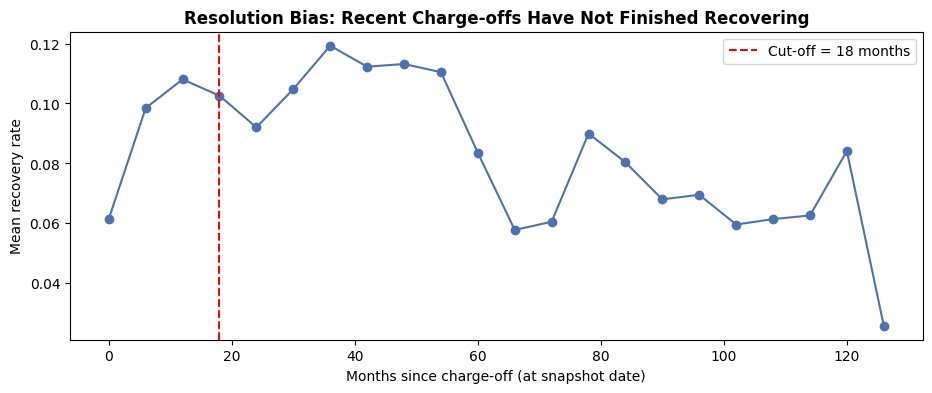

All defaults: 269,338 | Completed workouts kept: 138,102

--- Mean LGD by Assumed Workout Length (months) ---


,Mean LGD
0,0.8981
6,0.9053
12,0.9119
24,0.9237
36,0.9339


In [3]:
print("--- Building the Defaulted-Loan Sample ---")

# 1. Defaulted loans with a positive exposure
d = lc[lc['exit_type'].eq('default') & (lc['ead'] > 0)].copy()
as_of_n = AS_OF.year * 12 + AS_OF.month
d['months_since_co'] = as_of_n - (d['exit_m'].dt.year * 12 + d['exit_m'].dt.month) - CO_LAG_MONTHS
d['rec_rate_raw'] = d['net_recovery'] / d['ead']
d['default_q'] = d['exit_m'].dt.asfreq('Q').astype(str)

# 2. Attach the economy at the time of default (state and US unemployment in the default quarter)
d = d.merge(macro_state[['state', 'quarter', 'ur']].rename(
        columns={'state': 'addr_state', 'quarter': 'default_q', 'ur': 'ur_default'}),
        on=['addr_state', 'default_q'], how='left')
d = d.merge(macro_us[['quarter', 'ur_us']].rename(columns={'quarter': 'default_q'}), on='default_q', how='left')

# 3. Resolution bias: recovery rate vs. months since charge-off
bins_ms = np.arange(0, d['months_since_co'].max() + 6, 6)
curve = (d.assign(bucket=pd.cut(d['months_since_co'], bins_ms, right=False))
          .groupby('bucket', observed=True)['rec_rate_raw'].mean())
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot([b.left for b in curve.index], curve.values, marker='o', color='#4C72B0')
ax.axvline(MIN_MONTHS_SINCE_CO, color='red', ls='--', label=f'Cut-off = {MIN_MONTHS_SINCE_CO} months')
ax.set_xlabel('Months since charge-off (at snapshot date)'); ax.set_ylabel('Mean recovery rate')
ax.set_title('Resolution Bias: Recent Charge-offs Have Not Finished Recovering', fontweight='bold')
ax.legend(); plt.show()

# 4. Keep completed workouts only and compute realized LGD
resolved = d[(d['months_since_co'] >= MIN_MONTHS_SINCE_CO) & d['ur_default'].notna()].copy()

def realized_lgd(frame, workout_months):
    discount = (1 + frame['int_rate'] / 100) ** (workout_months / 12)
    return (1 - frame['net_recovery'] / discount / frame['ead']).clip(0, 1)

resolved['lgd'] = realized_lgd(resolved, WORKOUT_MONTHS)
resolved['full_loss'] = (resolved['lgd'] >= 0.9999).astype(int)

print(f"All defaults: {len(d):,} | Completed workouts kept: {len(resolved):,}")

# 5. Sensitivity of the average LGD to the workout-length assumption
sens_w = pd.Series({w: realized_lgd(resolved, w).mean() for w in [0, 6, 12, 24, 36]})
print("\n--- Mean LGD by Assumed Workout Length (months) ---")
display(sens_w.to_frame('Mean LGD').round(4))

### Results

Filtering the **269,338 positive-balance defaults** for completed workouts ($\ge 18$ months since charge-off and valid state unemployment) leaves **138,102 resolved defaults**:

1. **Resolution Bias Curve Validates the 18-Month Cutoff:** The chart shows that average raw recovery rates climb sharply from **~6%** for charge-offs under 6 months old to **~10%** at 6–12 months, and stay between **9% and 12%** for charge-offs that are 12 months to about 5 years old. Most recovery cash arrives within the first year after charge-off, so the 18-month cutoff is a conservative way to remove unfinished workouts.
2. **Lower Recoveries on Pre-2014 Defaults:** On the right half of the chart (charge-offs more than 60 months old, corresponding to defaults before 2014), mean recovery rates drop back to about **6%–9%**. These workouts are long finished; their lower recoveries likely reflect the high-unemployment economic environment of 2009–2012 as well as Lending Club's early-stage collection practices.
3. **Sensitivity to Discounting Horizon ($W$):**

| Assumed Workout Horizon ($W$) | Mean Realized LGD | Change vs. Base Case ($W=12$) |
|---|---|---|
| **0 months (Undiscounted)** | 89.81% | −1.38 pp |
| **6 months** | 90.53% | −0.66 pp |
| **12 months (Base Case)** | **91.19%** | **0.00 pp** |
| **24 months** | 92.37% | +1.18 pp |
| **36 months** | 93.39% | +2.20 pp |

Because Lending Club only reports cumulative recoveries rather than monthly recovery timestamps, the workout discounting period $W$ is a modeling assumption that shifts portfolio LGD by **−1.4 to +2.2 percentage points** around the **91.19%** base case.

# Step 3: Exploring the Realized LGD Distribution and Economic Cycle

Before selecting modeling algorithms, we need to understand the shape of the realized LGD distribution and how loss severity varies across loan segments and macroeconomic conditions.

In banking and regulatory reporting, two portfolio LGD averages are tracked:

$$\overline{LGD}_{\text{default-weighted}} = \frac{1}{N}\sum_{i=1}^{N} LGD_i, \qquad \overline{LGD}_{\text{exposure-weighted}} = \frac{\sum_{i=1}^{N} EAD_i \cdot LGD_i}{\sum_{i=1}^{N} EAD_i}$$

* **Default-Weighted LGD:** Weights every defaulted loan equally ($1/N$). Under Basel IRB retail rules, this is the benchmark used to calibrate long-run average (LRA) LGD.
* **Exposure-Weighted LGD:** Weights each default by its dollar balance ($EAD_i$). This is the measure that drives total portfolio dollar losses in stress testing (Part 4) and ABS cash-flow waterfalls (Part 5).

I also plot the histogram of realized LGD, compare mean LGD across credit grades, loan terms, and loan purposes, and plot quarterly LGD against the U.S. unemployment rate.

--- Portfolio LGD ---
Default-weighted LGD : 91.19%
Exposure-weighted LGD: 91.29%
Zero-recovery share (LGD = 100%): 21.57%


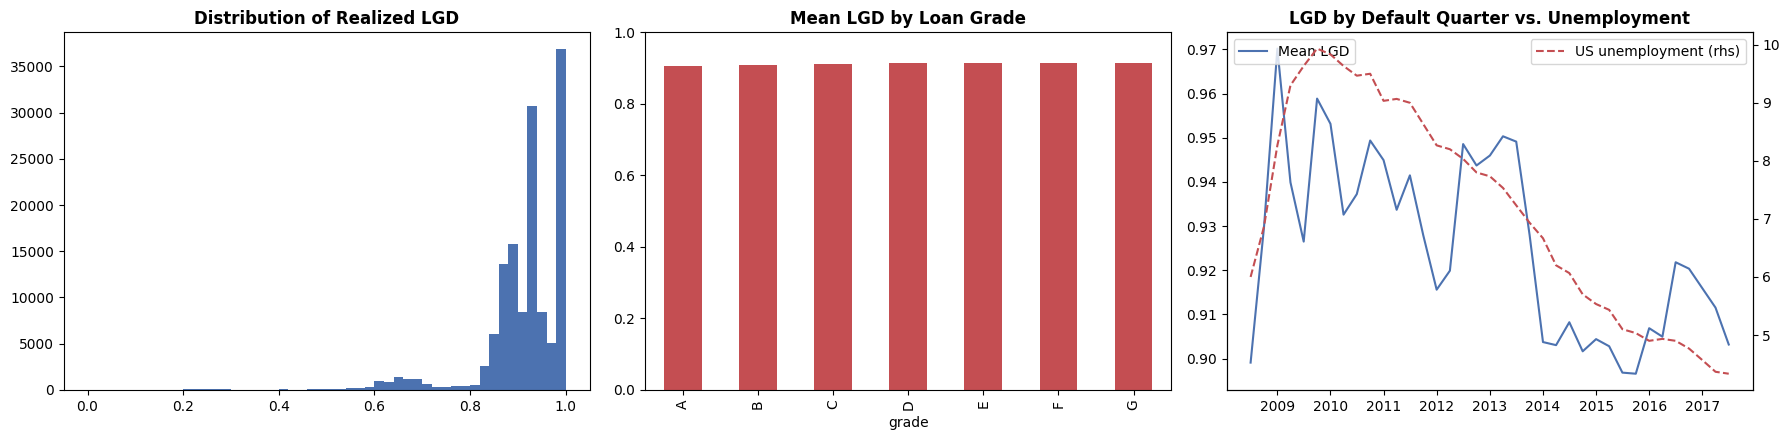


--- LGD by Term and Purpose ---


,mean,size
term_m,,
36,0.909755,84380
60,0.915291,53722


,mean,size
purpose,,
debt_consolidation,0.911615,86013
credit_card,0.912549,25378
other,0.910331,7901
home_improvement,0.912117,7507
small_business,0.918357,2752
major_purchase,0.915308,2607


In [4]:
print("--- Portfolio LGD ---")
lra_dw = resolved['lgd'].mean()
lra_ew = np.average(resolved['lgd'], weights=resolved['ead'])
print(f"Default-weighted LGD : {lra_dw:.2%}")
print(f"Exposure-weighted LGD: {lra_ew:.2%}")
print(f"Zero-recovery share (LGD = 100%): {resolved['full_loss'].mean():.2%}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. Distribution
axes[0].hist(resolved['lgd'], bins=50, color='#4C72B0')
axes[0].set_title('Distribution of Realized LGD', fontweight='bold')

# 2. LGD by grade
resolved.groupby('grade')['lgd'].mean().plot.bar(ax=axes[1], color='#C44E52')
axes[1].set_title('Mean LGD by Loan Grade', fontweight='bold'); axes[1].set_ylim(0, 1)

# 3. LGD over time vs. unemployment
ts = resolved.groupby('default_q').agg(lgd=('lgd', 'mean'), n=('lgd', 'size'), ur_us=('ur_us', 'first'))
ts = ts[ts['n'] >= 30]
x = pd.PeriodIndex(ts.index, freq='Q').to_timestamp()
axes[2].plot(x, ts['lgd'], color='#4C72B0', label='Mean LGD')
ax2 = axes[2].twinx(); ax2.plot(x, ts['ur_us'], color='#C44E52', ls='--', label='US unemployment (rhs)')
axes[2].set_title('LGD by Default Quarter vs. Unemployment', fontweight='bold')
axes[2].legend(loc='upper left'); ax2.legend(loc='upper right')
plt.tight_layout(); plt.show()

print("\n--- LGD by Term and Purpose ---")
display(resolved.groupby('term_m')['lgd'].agg(['mean', 'size']))
display(resolved.groupby('purpose')['lgd'].agg(['mean', 'size']).sort_values('size', ascending=False).head(6))

### Results

1. **Very High Loss Severity (~91.2%):** Across the 138,102 completed workouts, **default-weighted LGD is 91.19%** and **exposure-weighted LGD is 91.29%**. Because the two averages are nearly identical, loan size has very little effect on recovery rates. On average, unsecured personal loans recover less than 9 cents on the dollar after default.
2. **Concentrated Distribution with a Point Mass at 100% Loss:** The histogram shows that most defaulted loans lose between **85% and 100%** of their balance, with a massive point mass at **100% loss**: **21.57% of all defaults recover nothing at all ($LGD = 1.0$)**. Very few loans have low LGD because there is no physical collateral (like a car or house) to repossess.
3. **Small Spread Across Borrower Segments:**
   * **By Credit Grade:** Mean LGD edges up smoothly from **90.7%** for Grade A to **91.6%** for Grade G—a total spread of less than 1 percentage point across the entire credit spectrum.
   * **By Loan Term:** 60-month loans lose slightly more (**91.53%**, $n = 53,722$) than 36-month loans (**90.98%**, $n = 84,380$).
   * **By Loan Purpose:** Among the six largest purposes, mean LGD stays tightly grouped between **91.03%** (`other`) and **91.84%** (`small_business`, $n = 2,752$), with the two largest categories—`debt_consolidation` ($n = 86,013$) and `credit_card` ($n = 25,378$)—averaging **91.16%** and **91.25%**.
4. **Clear Co-Movement with the Economic Cycle:** The right-hand chart shows that quarterly mean LGD broadly followed the U.S. unemployment rate: defaults during the high-unemployment years of **2009–2011 (UR 9%–10%)** suffered **93%–97% LGD**, whereas defaults during the **2014–2016 expansion (UR about 5%–6%)** fell to about **90%–92% LGD**. The link is not exact: LGD rose in 2012–2013 while unemployment was falling and dropped sharply in 2014, which suggests that changes in collection practices also play a role. This cyclical sensitivity motivates our downturn LGD model in Step 7.

# Model Review: Methods and Mathematical Framework

Because realized LGD is bounded on $[0, 1]$ with a heavy spike at $1.0$ (21.6% zero-recovery loans), I compare six modeling architectures ranging from a simple segment lookup table to parametric hurdle models and gradient-boosted trees:

| # | Model Architecture | Target Specification | Key Advantage | Main Limitation |
|---|---|---|---|---|
| **1** | **Grade Average (Benchmark)** | Historical mean LGD by credit grade | Simple, transparent, zero-maintenance lookup table | Ignores loan age, income, term, and macro conditions |
| **2** | **Linear Regression (OLS)** | Continuous linear $x_i'\beta$ | Fast, closed-form analytical solution | Can predict outside $[0, 1]$; ignores non-constant variance |
| **3** | **Fractional Logit (QMLE)** | Logistic conditional mean $\Lambda(x_i'\beta) \in (0,1)$ | Predictions strictly bounded in $(0,1)$; consistent QMLE | Uses one equation for both zero-recovery and partial-recovery loans |
| **4** | **Two-Stage Hurdle (Logit)** | Stage 1: $P(LGD=1)$ via Logit<br>Stage 2: $E[LGD \mid LGD<1]$ via Frac. Logit | Separates drivers of *any recovery* from drivers of *recovery amount* | Assumes linear log-odds in both stages |
| **5** | **LightGBM Regressor** | Tree ensemble clipped to $[0, 1]$ | Captures non-linearities and feature interactions automatically | Requires post-hoc explainability (SHAP); prone to overfitting noise |
| **6** | **Two-Stage LightGBM** | Stage 1: Weighted LightGBM Classifier<br>Stage 2: Cross-Entropy LightGBM | Combines hurdle structure with non-linear tree splits | Requires prior-odds probability calibration after class weighting |

---

### Mathematical Specifications

1. **Grade Average (Benchmark):** Predicts each loan's LGD using the training-set mean of its credit grade $g(i)$:
   $$\widehat{LGD}_i = \frac{1}{N_{g(i)}}\sum_{j \in g(i)} LGD_j$$

2. **Ordinary Least Squares (OLS):** Estimates a linear conditional expectation $LGD_i = x_i'\beta + \varepsilon_i$ via $\hat{\beta} = (X'X)^{-1}X'y$.

3. **Fractional Logit (Papke & Wooldridge, 1996):** Models the conditional mean with the logistic link $\mu_i = E[LGD_i \mid x_i] = \Lambda(x_i'\beta) = \frac{1}{1 + e^{-x_i'\beta}}$ and maximizes the Bernoulli quasi-log-likelihood for continuous $y_i \in [0, 1]$:
   $$\ell(\beta) = \sum_{i=1}^{N} \Big[ y_i \log \Lambda(x_i'\beta) + (1 - y_i)\log\big(1 - \Lambda(x_i'\beta)\big) \Big]$$
   Solved via Iteratively Reweighted Least Squares (Newton–Raphson) with $W = \text{diag}\{\mu_i(1 - \mu_i)\}$ and sandwich robust variance $\widehat{V}(\hat{\beta})$:
   $$\beta^{(k+1)} = \beta^{(k)} + (X'WX)^{-1}X'(y - \mu), \qquad \widehat{V}(\hat{\beta}) = A^{-1}BA^{-1}, \quad A = X'WX, \quad B = \sum_{i=1}^{N} (y_i - \hat{\mu}_i)^2 x_i x_i'$$
   The Average Marginal Effect of feature $j$ is $AME_j = \hat{\beta}_j \cdot \overline{\hat{\mu}(1 - \hat{\mu})}$.

4. **Two-Stage Hurdle Model (Logit + Fractional Logit):** Explicitly models the point mass at $LGD = 1$ (zero recovery) using the law of total expectation:
   $$E[LGD \mid x] = P(LGD = 1 \mid x)\cdot 1 + \big(1 - P(LGD = 1 \mid x)\big)\cdot E[LGD \mid x,\ LGD < 1]$$

5. **Single-Stage LightGBM Challenger:** Fits an additive ensemble of regression trees $F_m(x) = F_{m-1}(x) + \nu\,h_m(x)$ to squared-error residuals, clipped to $[0, 1]$.

6. **Two-Stage LightGBM with Prior-Odds Correction:** Uses a class-weighted LightGBM classifier in Stage 1 (`scale_pos_weight` $w = \frac{1 - \pi}{\pi}$, where $\pi$ is the training full-loss rate) and a cross-entropy LightGBM regressor in Stage 2. Because weighting the minority class multiplies the predicted odds by $w$, we recalibrate the weighted Stage 1 probability $p_w$ back to the true prior before combining the stages:
   $$p_{\text{full}} = \frac{p_w}{p_w + (1 - p_w)\,w}, \qquad \widehat{LGD}(x) = p_{\text{full}} + (1 - p_{\text{full}})\cdot m_{\text{LGBM}}(x)$$

# Step 4: Feature Engineering, Out-of-Time Split, and Leakage-Free Design Matrix

An LGD model is triggered at the moment a loan defaults (or during pre-default portfolio stress testing). Therefore, every predictor must be known on or before the default date, and model validation must mirror real-world deployment by training on older defaults and testing on newer defaults (**out-of-time validation**).

1. **Three Feature Groups Known at Default:**
   * **Origination Characteristics:** Credit `grade`, `term_60` (60-month indicator), `int_rate`, `log_loan_amnt`, `log_annual_inc`, `dti`, `fico`, `revol_util`, `emp_years`, `home_ownership`, `purpose`, and `verification_status`.
   * **Loan Seasoning at Default:** Months on book at exit (`mob_exit`) and the share of original principal still owed at default (`ead_ratio` $= EAD_i / \text{funded\_amnt}_i$).
   * **Macroeconomic Environment:** State unemployment rate in the quarter of default (`ur_default`).
2. **Chronological Out-of-Time Split (70% / 30%):** I split the 138,102 completed workouts by default month (`exit_m`) at the 70th percentile (**January 2017**): defaults up to `2017-01` form the training set, and defaults after `2017-01` form the out-of-time test set.
3. **Leakage-Free `Design` Transformer:** Missing values are imputed with training medians, numeric features are standardized using training means and standard deviations (so regression coefficients represent a +1 SD shock), and categorical variables are one-hot encoded using training-set frequencies (with the largest category as the reference level).

In [5]:
print("--- Feature Engineering ---")

# 1. Engineered features
resolved['log_loan_amnt'] = np.log(resolved['funded_amnt'])
resolved['log_annual_inc'] = np.log1p(resolved['annual_inc'].clip(lower=0))
resolved['ead_ratio'] = resolved['ead'] / resolved['funded_amnt']   # share of principal still owed
resolved['term_60'] = (resolved['term_m'] == 60).astype(int)

NUM_FEATURES = ['int_rate', 'log_loan_amnt', 'log_annual_inc', 'dti', 'fico', 'revol_util',
                'emp_years', 'mob_exit', 'ead_ratio', 'ur_default', 'term_60']
CAT_FEATURES = ['grade', 'home_ownership', 'purpose', 'verification_status']

# 2. Out-of-time split
cutoff = resolved['exit_m'].quantile(0.70)
train = resolved[resolved['exit_m'] <= cutoff].copy()
test = resolved[resolved['exit_m'] > cutoff].copy()
print(f"Train: {len(train):,} defaults up to {cutoff} | Test: {len(test):,} defaults after {cutoff}")

# 3. Design matrix (statistics learned on the training set only -> no leakage)
class Design:
    """Imputes, standardizes and one-hot encodes using training-set statistics."""
    def __init__(self, frame, num, cat, min_count=200):
        self.num, self.cat = num, cat
        self.median = frame[num].median()
        filled = frame[num].fillna(self.median)
        self.mean, self.std = filled.mean(), filled.std().replace(0, 1)
        self.levels = {}
        for c in cat:
            counts = frame[c].fillna('missing').value_counts()
            self.levels[c] = counts[counts >= min_count].index.tolist()[1:]   # most frequent = reference
    def transform(self, frame):
        Z = (frame[self.num].fillna(self.median) - self.mean) / self.std
        parts = [pd.Series(1.0, index=frame.index, name='const'), Z]
        for c, lv in self.levels.items():
            col = frame[c].fillna('missing')
            parts.append(pd.DataFrame({f'{c}={l}': (col == l).astype(float) for l in lv}, index=frame.index))
        return pd.concat(parts, axis=1)

design = Design(train, NUM_FEATURES, CAT_FEATURES)
X_train, X_test = design.transform(train), design.transform(test)
y_train, y_test = train['lgd'].values, test['lgd'].values
print(f"Design matrix: {X_train.shape[1]} columns (incl. intercept)")

--- Feature Engineering ---
Train: 102,679 defaults up to 2017-01 | Test: 35,423 defaults after 2017-01
Design matrix: 33 columns (incl. intercept)


### Results

* **Out-of-Time Sample Split:** The 70/30 chronological cutoff at **January 2017 (`2017-01`)** yields **102,679 training defaults** and **35,423 out-of-time test defaults**.
* **Design Matrix Dimensions:** Both `X_train` and `X_test` have **33 columns** (an intercept, 11 standardized numeric features, and 21 categorical dummy indicators), with all imputation and scaling parameters locked to the training window.

# Step 5: Fitting the Six Statistical and Machine Learning LGD Models

In this step, I implement and fit all six LGD models on the 102,679 training defaults and generate out-of-time predictions on the 35,423 test defaults:

1. **Custom Newton–Raphson IRLS Verification:** Before fitting the real loan data, I run a Monte Carlo sanity check on 20,000 simulated Beta-distributed observations with known true parameters $\beta = [0.5, 1.0, -0.7]$ to verify that `fit_logit_irls` recovers them.
2. **Fitting Models 1–6:** I fit the Grade Average lookup table, OLS regression, Fractional Logit, Two-Stage Hurdle Logit, Single-Stage LightGBM, and Two-Stage LightGBM (using identical tree hyperparameters in Models 5 and 6 for a fair comparison).
3. **Driver Analysis (Fractional Logit AME Table):** To understand what economically drives loan recovery, I compute the robust $z$-statistics, $p$-values, and **Average Marginal Effects (AME)** for all 32 features in the Fractional Logit model.

In [6]:
print("--- Fitting LGD Models ---")

def fit_logit_irls(X, y, max_iter=100, tol=1e-9, ridge=1e-8):
    """(Fractional) logistic regression by Newton-Raphson (IRLS) with robust standard errors.
    y can be binary (logit) or any value in [0, 1] (fractional logit)."""
    X = np.asarray(X, float); y = np.asarray(y, float)
    k = X.shape[1]
    beta = np.zeros(k); beta[0] = logit(np.clip(y.mean(), 1e-4, 1 - 1e-4))   # start at the mean
    def quasi_loglik(b):
        mu = np.clip(expit(X @ b), 1e-12, 1 - 1e-12)
        return np.sum(y * np.log(mu) + (1 - y) * np.log(1 - mu))
    ll_old = quasi_loglik(beta)
    for it in range(max_iter):
        mu = expit(X @ beta)
        gradient = X.T @ (y - mu)                                        # X'(y - mu)
        hessian = (X * (mu * (1 - mu))[:, None]).T @ X + ridge * np.eye(k)   # X'WX
        step = np.linalg.solve(hessian, gradient)
        t = 1.0
        while quasi_loglik(beta + t * step) < ll_old - 1e-10 and t > 1e-4:   # step halving
            t /= 2
        beta = beta + t * step
        ll_new = quasi_loglik(beta)
        if np.max(np.abs(t * step)) < tol or abs(ll_new - ll_old) < tol:
            break
        ll_old = ll_new
    mu = expit(X @ beta)
    A_inv = np.linalg.inv((X * (mu * (1 - mu))[:, None]).T @ X + ridge * np.eye(k))
    score = X * (y - mu)[:, None]
    V_robust = A_inv @ (score.T @ score) @ A_inv                         # sandwich A^-1 B A^-1
    return {'beta': beta, 'se_robust': np.sqrt(np.diag(V_robust)),
            'n_iter': it + 1, 'avg_dmu': np.mean(mu * (1 - mu))}

def predict_logit(fit, X):
    return expit(np.asarray(X, float) @ fit['beta'])

def coef_table(fit, names):
    z = fit['beta'] / fit['se_robust']
    return pd.DataFrame({'Coefficient': fit['beta'], 'Robust SE': fit['se_robust'], 'z': z,
                         'p-value': 2 * stats.norm.sf(np.abs(z)), 'AME': fit['beta'] * fit['avg_dmu']}, index=names)

# 0. Sanity check: recover known coefficients from simulated fractional data
rng = np.random.default_rng(0)
X_sim = np.column_stack([np.ones(20000), rng.normal(size=(20000, 2))])
mu_sim = expit(X_sim @ np.array([0.5, 1.0, -0.7]))
y_sim = rng.beta(5 * mu_sim, 5 * (1 - mu_sim))
print(f"Sanity check -> true [0.5, 1.0, -0.7], estimated {fit_logit_irls(X_sim, y_sim)['beta'].round(3)}\n")

preds = {}

# 1. Segment average (benchmark)
grade_avg = train.groupby('grade')['lgd'].mean()
preds['1. Grade Average (Benchmark)'] = test['grade'].map(grade_avg).fillna(train['lgd'].mean()).values

# 2. OLS
beta_ols, *_ = np.linalg.lstsq(X_train.values, y_train, rcond=None)
preds['2. OLS'] = X_test.values @ beta_ols
print(f"OLS predictions outside [0, 1]: {np.mean((preds['2. OLS'] < 0) | (preds['2. OLS'] > 1)):.2%}")

# 3. Fractional logit
frac_logit = fit_logit_irls(X_train, y_train)
preds['3. Fractional Logit'] = predict_logit(frac_logit, X_test)
print(f"Fractional logit converged in {frac_logit['n_iter']} Newton iterations")

# 4. Two-stage hurdle model
stage1 = fit_logit_irls(X_train, train['full_loss'].values)            # P(LGD = 1)
partial = train['full_loss'].values == 0
stage2 = fit_logit_irls(X_train[partial], y_train[partial])            # E[LGD | LGD < 1]
p_full = predict_logit(stage1, X_test)
preds['4. Two-Stage Hurdle'] = p_full + (1 - p_full) * predict_logit(stage2, X_test)

# 5. LightGBM challenger
lgb_model = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31,
                              min_child_samples=100, reg_lambda=1.0, random_state=42, verbose=-1)
def lgb_matrix(X):   # LightGBM does not accept spaces or special characters in feature names
    return X.drop(columns='const').rename(columns=lambda c: re.sub(r'[^0-9a-zA-Z_]', '_', c))
lgb_model.fit(lgb_matrix(X_train), y_train)
preds['5. LightGBM'] = np.clip(lgb_model.predict(lgb_matrix(X_test)), 0, 1)

# 6. Two-stage LightGBM: the hurdle structure of model 4, with LightGBM in both stages
lgb_params = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                  reg_lambda=1.0, random_state=42, verbose=-1)       # same settings as model 5
X_tr_lgb, X_te_lgb = lgb_matrix(X_train), lgb_matrix(X_test)
full_rate = train['full_loss'].mean()
spw = (1 - full_rate) / full_rate                                     # partial-loss loans per full-loss loan
stage1_lgb = lgb.LGBMClassifier(scale_pos_weight=spw, **lgb_params).fit(X_tr_lgb, train['full_loss'].values)
p_full_w = stage1_lgb.predict_proba(X_te_lgb)[:, 1]                   # weighted probability (too high)
p_full_lgb = p_full_w / (p_full_w + (1 - p_full_w) * spw)            # correction: divide the odds by spw
stage2_lgb = lgb.LGBMRegressor(objective='cross_entropy', **lgb_params)   # targets and predictions in [0, 1]
stage2_lgb.fit(X_tr_lgb[partial], y_train[partial])
m_partial_lgb = stage2_lgb.predict(X_te_lgb)
if m_partial_lgb.min() < 0 or m_partial_lgb.max() > 1:                # safety check: convert raw scores if needed
    m_partial_lgb = expit(m_partial_lgb)
preds['6. Two-Stage LightGBM'] = p_full_lgb + (1 - p_full_lgb) * m_partial_lgb
print(f"Two-stage LightGBM: training full-loss rate {full_rate:.2%} -> scale_pos_weight = {spw:.2f}")
print(f"Mean P(full loss) on the test set: {p_full_w.mean():.2%} with the weight, {p_full_lgb.mean():.2%} after the correction")

# 7. What drives LGD? Fractional logit coefficients, sorted by average marginal effect
print("\n--- Fractional Logit: Drivers of LGD (AME = change in LGD per +1 SD / category) ---")
display(coef_table(frac_logit, X_train.columns).sort_values('AME', key=np.abs, ascending=False).round(4))

--- Fitting LGD Models ---
Sanity check -> true [0.5, 1.0, -0.7], estimated [ 0.501  1.01  -0.683]

OLS predictions outside [0, 1]: 0.01%
Fractional logit converged in 4 Newton iterations
Two-stage LightGBM: training full-loss rate 20.07% -> scale_pos_weight = 3.98
Mean P(full loss) on the test set: 48.59% with the weight, 20.58% after the correction

--- Fractional Logit: Drivers of LGD (AME = change in LGD per +1 SD / category) ---


,Coefficient,Robust SE,z,p-value,AME
const,2.3326,0.0110,212.4665,0.0000,0.1865
grade=G,0.1931,0.0470,4.1044,0.0000,0.0154
grade=F,0.1777,0.0345,5.1453,0.0000,0.0142
grade=A,-0.1200,0.0310,-3.8709,0.0001,-0.0096
purpose=wedding,-0.1187,0.0918,-1.2937,0.1958,-0.0095
grade=E,0.1070,0.0222,4.8148,0.0000,0.0086
mob_exit,-0.1041,0.0131,-7.9452,0.0000,-0.0083
purpose=small_business,0.1007,0.0270,3.7250,0.0002,0.0081
int_rate,-0.0896,0.0137,-6.5520,0.0000,-0.0072
log_annual_inc,-0.0894,0.0050,-17.8024,0.0000,-0.0072


### Results

1. **Numerical Verification & Fast Convergence:** On the simulated Beta dataset, our custom IRLS solver recovers `[0.501, 1.010, -0.683]` against the true `[0.5, 1.0, -0.7]`. On the 102,679 real training defaults, the Fractional Logit converges in just **4 Newton–Raphson iterations**.
2. **Why OLS Rarely Violates $[0, 1]$ Here:** Only **0.01%** of OLS test predictions fall outside $[0, 1]$. Because realized LGD is tightly clustered around 91% with a narrow standard deviation (~10%), linear predictions almost never reach 0% or 100%.
3. **Prior-Odds Calibration Fixes Class-Weight Distortion in Model 6:** In the training set, **20.07%** of defaults suffered a 100% loss, giving a class weight of `scale_pos_weight = 3.98`. Without correction, the weighted Stage 1 LightGBM classifier predicts a mean full-loss probability of **48.59%** on the test set, more than double the 20.07% training rate and far above the 25.92% test rate. Combined with stage 2, this inflated probability would push the final LGD upward. Applying our prior-odds correction brings the mean predicted full-loss probability back to **20.58%**.
4. **Economic & Borrower Drivers of LGD (Fractional Logit AMEs):**

| Driver Category | Feature | Coefficient | Robust $z$ | $p$-value | AME (LGD Impact) | Economic Interpretation |
|---|---|---|---|---|---|---|
| **Credit Tier** *(vs. C)* | `grade=G` / `grade=F` | +0.193 / +0.178 | +4.10 / +5.15 | $< 0.001$ | **+1.54 pp / +1.42 pp** | Deep subprime borrowers recover less after charge-off |
| | `grade=A` / `grade=B` | −0.120 / −0.052 | −3.87 / −3.39 | $< 0.001$ | **−0.96 pp / −0.41 pp** | Prime borrowers recover more after default |
| **Loan Seasoning** | `mob_exit` (+1 SD) | −0.104 | −7.95 | $< 0.001$ | **−0.83 pp** | Borrowers who paid longer before defaulting recover more |
| **Loan Purpose** | `purpose=small_business` | +0.101 | +3.73 | $< 0.001$ | **+0.81 pp** | Failed small businesses leave fewer personal recovery assets |
| **Borrower Capacity** | `log_annual_inc` (+1 SD) | −0.089 | −17.80 | $< 0.001$ | **−0.72 pp** | Higher-income borrowers are easier to collect from post-default |
| | `home_ownership=OWN` | −0.075 | −5.51 | $< 0.001$ | **−0.60 pp** | Homeowners have stronger financial stability than renters |
| **Loan Structure** | `term_60` (+1 SD) | +0.071 | +9.30 | $< 0.001$ | **+0.57 pp** (about +1.2 pp for a 60-month vs. a 36-month loan) | Longer terms carry higher loss severity |
| **Macroeconomy** | `ur_default` (+1 SD) | +0.059 | +11.94 | $< 0.001$ | **+0.47 pp** | Higher state unemployment at default depresses recoveries |
| **PD Credit Ratios** | `fico`, `dti`, `revol_util` | −0.005 to +0.002 | −0.91 to +0.38 | $0.36–0.71$ | **$\approx 0.00$ pp (Insig.)** | Credit bureau ratios predict *default (PD)*, not *post-default recovery* |

*(Note: `ead_ratio` has a small negative AME of −0.33 pp because it is collinear with `mob_exit` and `term_60`; in a standalone production regression, one of the collinear seasoning variables would be dropped. `int_rate` also has a significant negative AME (−0.72 pp per SD) once grade is included; this most likely reflects its overlap with the grade dummies rather than a real effect on recoveries.)*

# Step 6: Out-of-Time Model Evaluation, Stage-by-Stage Diagnostics, and SHAP Explainability

Because LGD models serve both loan-level underwriting (ranking riskier loans) and portfolio-level capital/provisioning (predicting total dollar loss), I evaluate all six models on the **35,423 out-of-time test defaults** across four complementary criteria:

| Evaluation Metric | Mathematical Definition | Core Risk Question |
|---|---|---|
| **Spearman Rank Correlation ($\rho$)** | $\text{corr}\big(\text{rank}(y),\ \text{rank}(\hat{y})\big)$ | Does the model rank high-loss loans above low-loss loans? |
| **RMSE & MAE** | $\sqrt{\frac{1}{N}\sum (y_i - \hat{y}_i)^2}, \quad \frac{1}{N}\sum |y_i - \hat{y}_i|$ | How large are the prediction errors on individual loans? |
| **Out-of-Sample $R^2$** | $1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y}_{\text{test}})^2}$ | What share of loan-to-loan LGD variance is explained? |
| **Portfolio Dollar Bias** | $\frac{\sum_i EAD_i \cdot \hat{y}_i}{\sum_i EAD_i \cdot y_i} - 1$ | Does the model accurately predict total portfolio dollar loss? |

In addition, I run three deep-dive diagnostics:
1. **Stage-by-Stage Hurdle Comparison:** I evaluate Stage 1 (AUC and Brier score for predicting $LGD = 1$) and Stage 2 (RMSE and Spearman $\rho$ on partial-recovery loans) separately for the Two-Stage Logit (Model 4) and Two-Stage LightGBM (Model 6).
2. **Decile Calibration Curve:** I bin test predictions into 10 deciles and plot mean predicted LGD against mean realized LGD.
3. **SHAP Explainability:** I compute TreeSHAP values on 2,000 test defaults to inspect the top global drivers of the LightGBM challenger.

--- Out-of-Time Model Evaluation ---


,RMSE,MAE,R2 (OOS),Spearman,Mean Predicted,Mean Actual,Portfolio Bias
4. Two-Stage Hurdle,0.1040,0.0663,0.0092,0.1224,0.9072,0.9111,-0.0057
2. OLS,0.1040,0.0662,0.0092,0.1208,0.9073,0.9111,-0.0058
3. Fractional Logit,0.1040,0.0662,0.0093,0.1207,0.9072,0.9111,-0.0059
5. LightGBM,0.1039,0.0654,0.0103,0.1082,0.9102,0.9111,-0.0020
6. Two-Stage LightGBM,0.1040,0.0658,0.0082,0.1043,0.9094,0.9111,-0.0029
1. Grade Average (Benchmark),0.1045,0.0639,0.0004,0.0685,0.9121,0.9111,-0.0007



--- Stage-by-Stage Check ---
Actual full-loss rate: 25.92% | Loans with a partial recovery: 26,243 (mean LGD 88.00%)


,Stage 1 AUC,Stage 1 Brier,Mean P(full loss),Stage 2 RMSE,Stage 2 Spearman,Stage 2 Mean Predicted
4. Two-Stage Hurdle (logit),0.5656,0.1925,0.2154,0.1046,0.1371,0.8814
6. Two-Stage LightGBM,0.5872,0.1916,0.2058,0.1045,0.1216,0.8860


Calculating SHAP values for LightGBM (this may take a moment)...


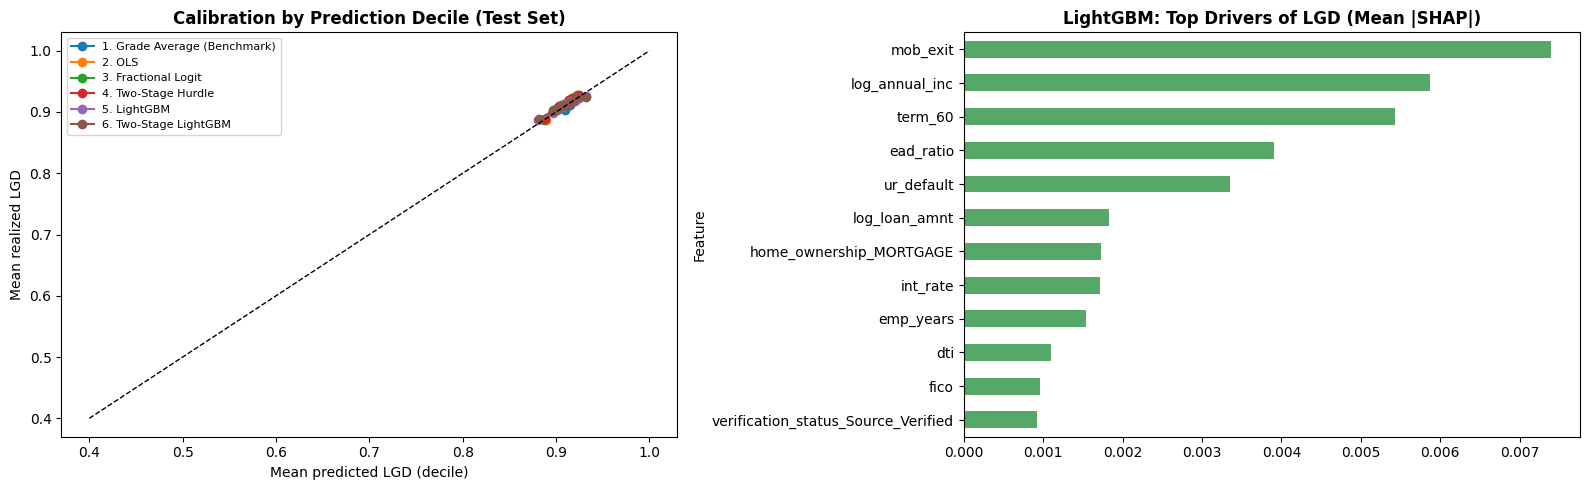

In [7]:
print("--- Out-of-Time Model Evaluation ---")

def evaluate(y, p, ead):
    return {'RMSE': np.sqrt(np.mean((y - p) ** 2)),
            'MAE': np.mean(np.abs(y - p)),
            'R2 (OOS)': 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2),
            'Spearman': stats.spearmanr(y, p).correlation,
            'Mean Predicted': p.mean(), 'Mean Actual': y.mean(),
            'Portfolio Bias': np.sum(ead * p) / np.sum(ead * y) - 1}

results_df = pd.DataFrame({m: evaluate(y_test, p, test['ead'].values) for m, p in preds.items()}).T
display(results_df.sort_values('Spearman', ascending=False).round(4))

# 1. Stage-by-stage check of the two two-stage models
full_test = test['full_loss'].values
partial_test = full_test == 0
m_partial_logit = predict_logit(stage2, X_test)
def stage_metrics(p1, m2):
    return {'Stage 1 AUC': roc_auc_score(full_test, p1),
            'Stage 1 Brier': np.mean((full_test - p1) ** 2),
            'Mean P(full loss)': p1.mean(),
            'Stage 2 RMSE': np.sqrt(np.mean((y_test[partial_test] - m2[partial_test]) ** 2)),
            'Stage 2 Spearman': stats.spearmanr(y_test[partial_test], m2[partial_test]).correlation,
            'Stage 2 Mean Predicted': m2[partial_test].mean()}
stage_df = pd.DataFrame({'4. Two-Stage Hurdle (logit)': stage_metrics(p_full, m_partial_logit),
                         '6. Two-Stage LightGBM': stage_metrics(p_full_lgb, m_partial_lgb)}).T
print(f"\n--- Stage-by-Stage Check ---")
print(f"Actual full-loss rate: {full_test.mean():.2%} | Loans with a partial recovery: {partial_test.sum():,} "
      f"(mean LGD {y_test[partial_test].mean():.2%})")
display(stage_df.round(4))

# 2. Calibration by prediction decile
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for name, p in preds.items():
    decile = pd.qcut(pd.Series(p).rank(method='first'), 10, labels=False)
    cal = pd.DataFrame({'pred': p, 'actual': y_test, 'decile': decile}).groupby('decile').mean()
    axes[0].plot(cal['pred'], cal['actual'], marker='o', label=name)
lo = min(y_test.mean() - 0.3, 0.4)
axes[0].plot([lo, 1], [lo, 1], 'k--', lw=1)
axes[0].set_xlabel('Mean predicted LGD (decile)'); axes[0].set_ylabel('Mean realized LGD')
axes[0].set_title('Calibration by Prediction Decile (Test Set)', fontweight='bold'); axes[0].legend(fontsize=8)

# 3. SHAP explanation of the LightGBM challenger
print("Calculating SHAP values for LightGBM (this may take a moment)...")
X_test_sample = lgb_matrix(X_test).sample(min(2000, len(X_test)), random_state=42)
shap_values = shap.TreeExplainer(lgb_model).shap_values(X_test_sample)
shap_df = pd.DataFrame({'Feature': X_test_sample.columns,
                        'Mean Absolute SHAP': np.abs(shap_values).mean(axis=0)}).sort_values('Mean Absolute SHAP')
shap_df.tail(12).plot.barh(x='Feature', y='Mean Absolute SHAP', ax=axes[1], color='#55A868', legend=False)
axes[1].set_title('LightGBM: Top Drivers of LGD (Mean |SHAP|)', fontweight='bold')
plt.tight_layout(); plt.show()

### Results

#### 1. Out-of-Time Benchmark (35,423 Test Defaults, Actual Mean LGD = 91.11%)

| Rank (by $\rho$) | Model | Spearman $\rho$ | RMSE | MAE | $R^2$ (OOS) | Mean Predicted | Portfolio Dollar Bias |
|---|---|---|---|---|---|---|---|
| **1** | **4. Two-Stage Hurdle (Logit)** | **0.1224** | 0.1040 | 0.0663 | 0.92% | 90.72% | −0.57% |
| **2** | **2. OLS** | 0.1208 | 0.1040 | 0.0662 | 0.92% | 90.73% | −0.58% |
| **3** | **3. Fractional Logit** | 0.1207 | 0.1040 | 0.0662 | 0.93% | 90.72% | −0.59% |
| **4** | **5. LightGBM Regressor** | 0.1082 | **0.1039** | 0.0654 | **1.03%** | 91.02% | −0.20% |
| **5** | **6. Two-Stage LightGBM** | 0.1043 | 0.1040 | 0.0658 | 0.82% | 90.94% | −0.29% |
| **6** | **1. Grade Average (Benchmark)** | 0.0685 | 0.1045 | **0.0639** | 0.04% | 91.21% | **−0.07%** |

#### 2. Stage-by-Stage Diagnostic (Two-Stage Logit vs. Two-Stage LightGBM)
*(Test set actual full-loss rate = **25.92%**; partial-recovery subset = **26,243 loans** with mean LGD = **88.00%**)*

| Diagnostic Metric | 4. Two-Stage Hurdle (Logit) | 6. Two-Stage LightGBM | Winner & Insight |
|---|---|---|---|
| **Stage 1 AUC** ($P(LGD = 1)$) | 0.5656 | **0.5872** | LightGBM better separates zero-recovery from partial-recovery loans |
| **Stage 1 Brier Score** | 0.1925 | **0.1916** | LightGBM has slightly lower probability error in Stage 1 |
| **Stage 1 Mean Predicted $P(\text{full loss})$** | 21.54% | 20.58% | Both reflect the ~20.1% training rate vs. 25.9% in the post-2017 test window |
| **Stage 2 RMSE** *(partial-loss loans)* | 0.1046 | **0.1045** | Identical error magnitude on partial recoveries |
| **Stage 2 Spearman $\rho$** *(partial-loss loans)* | **0.1371** | 0.1216 | Parametric Fractional Logit ranks partial recoveries better |
| **Stage 2 Mean Predicted LGD** | 88.14% | 88.60% | Both closely match the 88.00% realized partial-loss mean |

* **Why Two-Stage Logit Wins Overall Ranking:** Adding a hurdle stage edges out single-stage Fractional Logit ($\rho = 0.1224$ vs. $0.1207$), and all regression models nearly double the ranking power of the Grade Average ($\rho = 0.0685$). Interestingly, while LightGBM performs better in Stage 1 (AUC $0.5872$ vs. $0.5656$), it ranks partial recoveries worse in Stage 2 ($\rho = 0.1216$ vs. $0.1371$). Because 74% of test defaults have partial recoveries, Stage 2 dominates the combined ranking.
* **Why $R^2$ Is About 1%:** The regression and tree models explain only about 1% of loan-to-loan LGD variance (the grade average 0.04%). For unsecured consumer loans, whether a collection agency recovers 5% or 15% depends heavily on post-default events (job recovery, legal settlements, debt-sale batch pricing) that are unknowable at default.
* **Excellent Portfolio Calibration & SHAP Agreement:** All six models predict total portfolio dollar loss within **$-0.07\%$ to $-0.59\%$**, and their decile calibration curves track the 45° line closely. The SHAP chart shows that LightGBM's top drivers (`mob_exit`, `log_annual_inc`, `term_60`, `ead_ratio`, `ur_default`) are also significant drivers in the Fractional Logit.
* **Practical Model Selection for Downstream Parts:** If a bank needs loan-level LGD discrimination, the **Two-Stage Hurdle Logit** is the clear champion. However, for portfolio-level applications (Part 3 cut-off valuation, Part 4 stress testing, and Part 5 ABS waterfalls), **grade-level LGD (~90.7%–91.6%) augmented with macroeconomic sensitivity** achieves virtually identical portfolio accuracy (`-0.07%` bias) without requiring loan-age features (`mob_exit`, `ead_ratio`) that are unknown prior to default.

# Step 7: Downturn LGD Estimation and Macro Satellite Model

Under Basel regulatory capital rules and stress-testing standards, banks must estimate **Downturn LGD**—the loss severity expected during a severe economic contraction—because defaulted loans tend to recover less at the same time as default rates rise. Furthermore, the 9-quarter macroeconomic stress test in Part 4 needs a model that updates LGD dynamically as state unemployment changes each quarter.

We cannot use the full Model 4 (32 features) directly in a multi-quarter forward stress test because several of its key inputs (`mob_exit` and `ead_ratio` at default) depend on *when* a currently performing loan will default in the future. Instead, we need a **macroeconomic satellite model** that uses variables known for every active loan in every scenario quarter: **credit grade ($g$)** and **state unemployment ($UR$)**.

I estimate and cross-check Downturn LGD using three complementary methods:

1. **Approach 1 — Empirical Downturn Quarters:** I identify the top quartile of historical U.S. unemployment quarters (the 10 worst quarters, primarily 2009–2011), compare their realized LGD against normal quarters, and test the difference with a Welch two-sample $t$-test.
2. **Approach 2 — Two-Stage Macro Satellite Model:** Matching the winning hurdle architecture from Step 6, I fit a two-stage model where both the full-loss probability $p_g(UR)$ and the partial-loss severity $m_g(UR)$ depend on credit grade $g$ and state unemployment $UR$ (in percentage points):
   $$p_g(UR) = \Lambda\big(\alpha^{(1)}_g + \gamma_1 \cdot UR\big), \qquad m_g(UR) = \Lambda\big(\alpha^{(2)}_g + \gamma_2 \cdot UR\big)$$
   $$LGD_g(UR) = p_g(UR) + \big(1 - p_g(UR)\big)\cdot m_g(UR), \qquad LGD^{\text{downturn}}_g = \max\Big(LGD^{\text{LRA}}_g,\ LGD_g(UR^* = 10\%)\Big)$$
   *(The regulatory floor ensures that a stress scenario never reduces LGD below a grade's long-run average.)*
3. **Cross-Check Against Full Model 4:** To verify that dropping loan-level controls does not distort the unemployment sensitivity, I shock `ur_default` to `10.0%` inside the full Two-Stage Hurdle Model (holding all other borrower features at their observed values) and compare its grade-level predictions against the satellite model.

In [8]:
print("--- Approach 1: Observed Downturn Periods ---")
quarter_ur = resolved.groupby('default_q')['ur_us'].first()
downturn_q = quarter_ur[quarter_ur >= quarter_ur.quantile(0.75)].index    # top quartile of unemployment
is_dt = resolved['default_q'].isin(downturn_q)
t_test = stats.ttest_ind(resolved.loc[is_dt, 'lgd'], resolved.loc[~is_dt, 'lgd'], equal_var=False)
print(f"Downturn quarters: {len(downturn_q)} ({is_dt.sum():,} defaults)")
print(f"LGD in downturn quarters: {resolved.loc[is_dt, 'lgd'].mean():.2%} | "
      f"other quarters: {resolved.loc[~is_dt, 'lgd'].mean():.2%} | Welch t = {t_test.statistic:.2f}, p = {t_test.pvalue:.3f}")

print("\n--- Approach 2: Two-Stage Macro Satellite Model ---")

# 1. Design: intercept, state unemployment at default (in % points) and grade dummies (reference = grade A)
grades = sorted(resolved['grade'].unique())
X_sat = pd.DataFrame({'const': 1.0, 'ur': resolved['ur_default']}, index=resolved.index)
for g in grades[1:]:
    X_sat[f'grade={g}'] = (resolved['grade'] == g).astype(float)
full_all = resolved['full_loss'].values
partial_all = full_all == 0

# 2. Stage 1: probability of a full loss | Stage 2: LGD when part of the balance is recovered
sat_s1 = fit_logit_irls(X_sat, full_all)
sat_s2 = fit_logit_irls(X_sat[partial_all], resolved['lgd'].values[partial_all])
cols = ['Coefficient', 'Robust SE', 'z', 'p-value']
sat_table = pd.concat({'Stage 1: P(full loss)': coef_table(sat_s1, X_sat.columns)[cols],
                       'Stage 2: LGD if partial loss': coef_table(sat_s2, X_sat.columns)[cols]}, axis=1)
display(sat_table.round(4))

def stage_params(fit):
    b = pd.Series(fit['beta'], index=X_sat.columns)
    alpha = {grades[0]: b['const']}
    alpha.update({g: b['const'] + b[f'grade={g}'] for g in grades[1:]})
    return alpha, b['ur']

alpha1, gamma1 = stage_params(sat_s1)
alpha2, gamma2 = stage_params(sat_s2)
p_gamma1 = sat_table.loc['ur', ('Stage 1: P(full loss)', 'p-value')]
p_gamma2 = sat_table.loc['ur', ('Stage 2: LGD if partial loss', 'p-value')]

def lgd_two_stage(grade, ur):
    """Two-stage satellite: LGD = P(full loss) + (1 - P(full loss)) x E[LGD | partial loss]."""
    g = pd.Series(np.asarray(grade))
    p = expit(g.map(alpha1).values + gamma1 * ur)
    m = expit(g.map(alpha2).values + gamma2 * ur)
    return p + (1 - p) * m

# 3. Effect of +1 point of unemployment on LGD, averaged over all defaults
ur_all = resolved['ur_default'].values
ur_effect = 100 * np.mean(lgd_two_stage(resolved['grade'], ur_all + 0.5) - lgd_two_stage(resolved['grade'], ur_all - 0.5))
print(f"\nStage 1: gamma = {gamma1:.4f} (p = {p_gamma1:.3f}) | Stage 2: gamma = {gamma2:.4f} (p = {p_gamma2:.3f})")
print(f"Two-stage satellite: +1pp unemployment raises LGD by {ur_effect:.2f} pp on average")

print("\n--- Check: The Full Two-Stage Model (Model 4) Under Stress ---")

# 4. Model 4 uses all variables. We change only the unemployment rate and keep everything else as observed.
def model4_lgd(frame):
    X = design.transform(frame)
    p = predict_logit(stage1, X)
    return p + (1 - p) * predict_logit(stage2, X)

m4_base = model4_lgd(resolved)
m4_stress = pd.Series(model4_lgd(resolved.assign(ur_default=STRESS_UR)), index=resolved.index)
m4_effect = 100 * np.mean(model4_lgd(resolved.assign(ur_default=resolved['ur_default'] + 1)) - m4_base)
print(f"Full model 4: +1pp unemployment raises LGD by {m4_effect:.2f} pp on average")

# 5. Downturn LGD by grade (floored at the long-run average: a stress must never lower LGD)
lra_by_grade = resolved.groupby('grade')['lgd'].mean()
sat_col, m4_col = f'Satellite @ UR = {STRESS_UR:.0f}%', f'Model 4 @ UR = {STRESS_UR:.0f}%'
downturn = pd.DataFrame({'LRA LGD': lra_by_grade})
downturn[sat_col] = lgd_two_stage(downturn.index, STRESS_UR)
downturn[m4_col] = m4_stress.groupby(resolved['grade']).mean()
downturn['Downturn LGD (floored)'] = downturn[['LRA LGD', sat_col]].max(axis=1)
downturn['Add-on (pp)'] = 100 * (downturn['Downturn LGD (floored)'] - downturn['LRA LGD'])
display(downturn.round(4))

# Save the LGD model for Part 3 (profit cut-off), Part 4 (stress test) and Part 5 (securitization)
lgd_satellite = {
    'description': ('Two-stage satellite: LGD = p + (1 - p) * m, with p = expit(a1_grade + g1 * UR) and '
                    'm = expit(a2_grade + g2 * UR); UR = state unemployment rate at default (%)'),
    'stage1': {'alpha_by_grade': {g: float(a) for g, a in alpha1.items()},
               'gamma_ur': float(gamma1), 'gamma_p_value': float(p_gamma1)},
    'stage2': {'alpha_by_grade': {g: float(a) for g, a in alpha2.items()},
               'gamma_ur': float(gamma2), 'gamma_p_value': float(p_gamma2)},
    'ur_effect_pp': float(ur_effect),
    'lra_by_grade': {g: float(v) for g, v in lra_by_grade.items()},
    'lra_default_weighted': float(lra_dw), 'lra_exposure_weighted': float(lra_ew),
    'workout_months': WORKOUT_MONTHS}
with open(os.path.join(PROJECT_DIR, 'lgd_satellite.json'), 'w') as f:
    json.dump(lgd_satellite, f, indent=2)
print("Saved lgd_satellite.json to Google Drive for Parts 3, 4 and 5.")

--- Approach 1: Observed Downturn Periods ---
Downturn quarters: 10 (1,513 defaults)
LGD in downturn quarters: 94.16% | other quarters: 91.16% | Welch t = 8.52, p = 0.000

--- Approach 2: Two-Stage Macro Satellite Model ---


Stage 1: P(full loss)                             \
                  Coefficient Robust SE        z p-value   
const                  0.0639    0.0416   1.5351  0.1248   
ur                    -0.1920    0.0060 -32.1743  0.0000   
grade=B               -0.2936    0.0303  -9.6918  0.0000   
grade=C               -0.4014    0.0291 -13.8038  0.0000   
grade=D               -0.4157    0.0298 -13.9627  0.0000   
grade=E               -0.4084    0.0315 -12.9781  0.0000   
grade=F               -0.4992    0.0378 -13.2222  0.0000   
grade=G               -0.5726    0.0580  -9.8652  0.0000   

        Stage 2: LGD if partial loss                             
                         Coefficient Robust SE        z p-value  
const                         1.4476    0.0240  60.3255     0.0  
ur                            0.0843    0.0032  26.3250     0.0  
grade=B                       0.1305    0.0186   7.0136     0.0  
grade=C                       0.1842    0.0179  10.3106     0.0  
grade=D                       0.2074    0.0180  11.5001     0.0  
grade=E                       0.2187    0.0185  11.8326     0.0  
grade=F                       0.2450    0.0205  11.9682     0.0  
grade=G                       0.2715    0.0272   9.9821     0.0


Stage 1: gamma = -0.1920 (p = 0.000) | Stage 2: gamma = 0.0843 (p = 0.000)
Two-stage satellite: +1pp unemployment raises LGD by 0.29 pp on average

--- Check: The Full Two-Stage Model (Model 4) Under Stress ---
Full model 4: +1pp unemployment raises LGD by 0.34 pp on average


,LRA LGD,Satellite @ UR = 10%,Model 4 @ UR = 10%,Downturn LGD (floored),Add-on (pp)
grade,,,,,
A,0.9070,0.9205,0.9228,0.9205,1.3514
B,0.9099,0.9269,0.9271,0.9269,1.7059
C,0.9114,0.9297,0.9292,0.9297,1.8314
D,0.9130,0.9311,0.9303,0.9311,1.8098
E,0.9139,0.9319,0.9311,0.9319,1.7994
F,0.9145,0.9330,0.9322,0.9330,1.8475
G,0.9156,0.9342,0.9319,0.9342,1.8618


Saved lgd_satellite.json to Google Drive for Parts 3, 4 and 5.


### Results

1. **Empirical Downturn Quarters (+3.00 pp Shock):** Across the 10 highest-unemployment quarters (**1,513 resolved defaults**, mostly from 2009–2011), realized LGD averaged **94.16%** compared to **91.16%** in all other quarters. This **+3.00 percentage-point increase** is highly statistically significant (Welch $t = 8.52, p < 0.001$).
2. **Two-Stage Macro Satellite Diagnostics (Opposing Stage Effects):**
   * **Stage 2 (Partial-Recovery Severity):** Higher state unemployment strongly increases loss severity among loans that recover part of their balance ($\hat{\gamma}_2 = +0.0843, z = +26.33, p < 0.001$). During recessions, distressed borrowers repay less and debt buyers pay fewer cents on the dollar.
   * **Stage 1 (Zero-Recovery Probability):** Higher unemployment carries a negative coefficient in Stage 1 ($\hat{\gamma}_1 = -0.1920, z = -32.17, p < 0.001$). Rather than true economic relief, this reflects a **historical time trend**: high unemployment occurred in 2009–2012 and low unemployment in 2015–2017, a period over which Lending Club's collection and debt-sale practices evolved (leaving more recent charge-offs with zero recovery). Part 4 uncovers the exact same opposite-time-trend phenomenon in its macro PD model.
   * **Net Economic Effect:** Combining both stages, Stage 2 dominates: **each +1 percentage point increase in state unemployment raises portfolio LGD by +0.29 percentage points on average**.
3. **Full Model 4 Cross-Check Confirms the Satellite Model:** Shocking unemployment in the full Model 4 yields **+0.34 percentage points of LGD per +1 pp of unemployment**, and its 10%-unemployment predictions match the simple satellite model within **0.02 to 0.23 percentage points** across every single credit grade:

| Credit Grade | Long-Run Average (LRA) LGD | Satellite Model @ 10% UR | Full Model 4 @ 10% UR | Final Downturn LGD (Floored) | Downturn Add-On (pp) |
|---|---|---|---|---|---|
| **Grade A** | 90.70% | 92.05% | 92.28% | **92.05%** | **+1.35 pp** |
| **Grade B** | 90.99% | 92.69% | 92.71% | **92.69%** | **+1.71 pp** |
| **Grade C** | 91.14% | 92.97% | 92.92% | **92.97%** | **+1.83 pp** |
| **Grade D** | 91.30% | 93.11% | 93.03% | **93.11%** | **+1.81 pp** |
| **Grade E** | 91.39% | 93.19% | 93.11% | **93.19%** | **+1.80 pp** |
| **Grade F** | 91.45% | 93.30% | 93.22% | **93.30%** | **+1.85 pp** |
| **Grade G** | 91.56% | 93.42% | 93.19% | **93.42%** | **+1.86 pp** |

The satellite model and grade-level LRA benchmarks are saved to Google Drive as **`lgd_satellite.json`** for direct use in Parts 3, 4, and 5.

# Conclusions & Key Takeaways

Part 1 establishes our empirical and econometric LGD framework across **138,102 completed default workouts**:

1. **Unsecured Consumer Loans Suffer ~91% Loss Severity:** Realized workout LGD averages **91.19% (default-weighted)** and **91.29% (exposure-weighted)**, with **21.57%** of defaulted loans recovering zero cash. Because there is no collateral, lenders recover only ~9 cents per defaulted dollar.
2. **Hurdle Logit Ranks Best, Grade Benchmark Calibrates Best:** Out-of-time testing on 35,423 defaults shows that the **Two-Stage Hurdle Logit** achieves the highest loan-level ranking power (Spearman $\rho = 0.1224$), outperforming OLS, Fractional Logit, and both LightGBM architectures. However, because post-default recoveries are dominated by unobservable post-charge-off events ($R^2 \approx 1\%$), a simple **grade-level LGD schedule (90.70% to 91.56%)** is nearly as accurate for portfolio dollar totals (`-0.07%` bias) and is ideal for downstream portfolio models.
3. **LGD Rises When Unemployment Rises:** Both empirical downturn quarters (**94.16%** vs. **91.16%**) and our two-stage macroeconomic satellite model (**+0.29 pp LGD per +1 pp unemployment**) confirm that recovery rates fall when unemployment rises. At 10% unemployment, Downturn LGD rises by **+1.35 to +1.86 percentage points** across grades to **92.05%–93.42%**.

**Next Step (Part 2 — PD Algorithm Benchmark):** With LGD measured and saved in `lgd_satellite.json`, Part 2 turns to the **Probability of Default (PD)**—benchmarking seven classification algorithms out of time on matured 36-month loans against Lending Club's internal credit grades.

## Limitations

1. **Unobserved Recovery Timestamps:** Lending Club reports cumulative recovery dollars per loan rather than dated monthly recovery cash flows. Discounting therefore relies on an assumed 12-month average workout horizon (`WORKOUT_MONTHS = 12`), which moves average LGD by −1.4 to +2.2 percentage points (0 to 36 months).
2. **Servicer & Debt-Sale Policy Shifts:** Post-default recoveries depend not only on borrower characteristics and the macroeconomy, but also on Lending Club's internal collection agency contracts and secondary debt-sale pricing, which changed over the 2007–2018 sample.
3. **Principal-Only EAD Accounting:** Following standard practice on this dataset, $EAD$ is measured as remaining funded principal (`funded_amnt - total_rec_prncp`) and excludes accrued unpaid interest and late fees at charge-off.
4. **Limited 2008–09 Recession Sample:** As shown in Part 0, Lending Club's loan book was still small during the 2008–09 financial crisis, leaving only 1,513 completed workouts in the top quartile of historical unemployment quarters.